# International Factor Exposure & Return Attribution Lab

Which risks drive the returns of international equity ETFs, and are those risks **global** or **local**?

**Research questions**
1. How much of each ETF's return do Fama–French 5 + momentum factors explain?
2. Integration vs segmentation: do *regional* factors explain returns better than *global* (developed-market) factors?
3. Currency: does exposure to the broad US dollar add explanatory power?
4. Stability: did exposures change after 2016?

**Data**: Kenneth French international factor library (USD, monthly), Yahoo Finance total returns, FRED broad dollar index.
**Method**: OLS with Newey–West (HAC) standard errors, rolling 36-month betas, return attribution, Chow-type Wald stability test.

## 0. Setup (Colab or local)

In [1]:
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/YOUR_USER/intl-factor-lab.git"  # <- set after pushing to GitHub

if "google.colab" in sys.modules and not Path("intl_factors").exists():
    if not Path("intl-factor-lab").exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, "intl-factor-lab"], check=True)
    os.chdir("intl-factor-lab")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "yfinance", "statsmodels"], check=True)

ROOT = Path.cwd() if Path("intl_factors").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from intl_factors import data, models, plots

pd.set_option("display.float_format", "{:.3f}".format)

Matplotlib is building the font cache; this may take a moment.


## 1. Configuration

In [2]:
ETFS = data.ETFS                 # ticker -> (description, local Ken French region)
GLOBAL_REGION = "Developed"      # benchmark "global" factor set
SPLIT = "2016-01"                # subperiod break for the stability test
WINDOW = 36                      # months for rolling betas
FIG_DIR = ROOT / "reports" / "figures"
TAB_DIR = ROOT / "reports" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=150)

pd.DataFrame(ETFS, index=["description", "local region"]).T

,description,local region
EFA,MSCI EAFE (developed ex US & Canada),Developed_ex_US
VGK,FTSE Developed Europe,Europe
EWJ,MSCI Japan,Japan
EPP,MSCI Pacific ex Japan,Asia_Pacific_ex_Japan
EEM,MSCI Emerging Markets,Emerging
EWZ,MSCI Brazil,Emerging


## 2. Data collection
Downloads are cached in `data/cache/`. Set `refresh=True` to pull the latest vintage
(record the date: French factors are revised when Bloomberg data are updated).

In [3]:
rets, factors, usd = data.load_all(ETFS, refresh=False)
print("ETF returns:", rets.index.min(), "->", rets.index.max())
for region, f in factors.items():
    print(f"{region:<24} factors: {f.index.min()} -> {f.index.max()}")
print("USD factor:", usd.index.min(), "->", usd.index.max())

ETF returns: 2005-02 -> 2026-10
Asia_Pacific_ex_Japan    factors: 1990-11 -> 2026-09
Developed                factors: 1990-11 -> 2026-09
Developed_ex_US          factors: 1990-11 -> 2026-09
Emerging                 factors: 1990-01 -> 2026-09
Europe                   factors: 1990-11 -> 2026-09
Japan                    factors: 1990-11 -> 2026-09
USD factor: 2006-02 -> 2026-10


## 3. Cleaning checks and descriptive statistics
- Returns are monthly decimals in USD; ETF returns include reinvested dividends (Yahoo adjusted close).
- No prices are filled before inception or across gaps; the current, incomplete month is dropped.
- The factor correlation matrix checks multicollinearity (high correlations widen beta confidence intervals).

,first,last,months,missing_inside
EFA,2005-02,2026-10,261,0
VGK,2005-04,2026-10,259,0
EWJ,2005-02,2026-10,261,0
EPP,2005-02,2026-10,261,0
EEM,2005-02,2026-10,261,0
EWZ,2005-02,2026-10,261,0


,ann_return,ann_vol,worst_month,best_month,sharpe_like
EFA,0.074,0.167,-0.208,0.143,0.444
VGK,0.080,0.184,-0.218,0.164,0.433
EWJ,0.064,0.152,-0.156,0.116,0.420
EPP,0.089,0.201,-0.265,0.161,0.441
EEM,0.088,0.210,-0.256,0.169,0.420
EWZ,0.113,0.327,-0.386,0.284,0.344


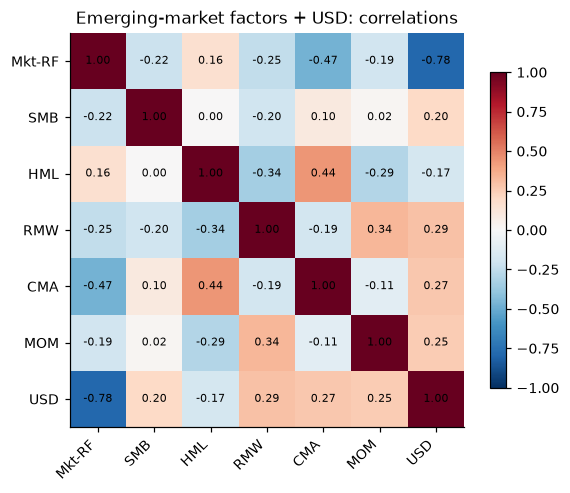

In [4]:
coverage = pd.DataFrame({
    "first": rets.apply(lambda s: s.first_valid_index()),
    "last": rets.apply(lambda s: s.last_valid_index()),
    "months": rets.notna().sum(),
    "missing_inside": rets.apply(lambda s: s.loc[s.first_valid_index():s.last_valid_index()].isna().sum()),
})
assert coverage["missing_inside"].eq(0).all(), "gap inside an ETF's history"
display(coverage)

stats = pd.DataFrame({
    "ann_return": rets.mean() * 12,
    "ann_vol": rets.std() * np.sqrt(12),
    "worst_month": rets.min(),
    "best_month": rets.max(),
})
stats["sharpe_like"] = stats["ann_return"] / stats["ann_vol"]
display(stats)

em = models.align(rets["EEM"], factors["Emerging"], usd)
fig = plots.correlation_heatmap(em[models.FF6 + ["USD"]], "Emerging-market factors + USD: correlations")
save(fig, "01_factor_correlations_emerging")

## 4. Full-sample factor models (local factors)
Each ETF is regressed on its **own region's** factors. All three models use the same months
(the USD series starts in 2006), so adjusted R² and alphas are comparable across models.
Alpha is annualized (×12); t-stats use Newey–West standard errors.

In [5]:
aligned, fits = {}, {}
for t, (_, region) in ETFS.items():
    aligned[t] = models.align(rets[t], factors[region], usd)
    fits[t] = models.fit_models(aligned[t])

summary = pd.concat({t: models.model_summary(r) for t, r in fits.items()}, names=["ETF", "model"])
display(summary)

alpha_ann  alpha_t  adj_r2  resid_vol_ann  ljung_box_p12  \
ETF model                                                               
EFA CAPM        -0.006   -1.387   0.969          0.030          0.000   
    FF6         -0.012   -2.854   0.980          0.024          0.000   
    FF6+USD     -0.011   -2.634   0.980          0.024          0.000   
VGK CAPM        -0.004   -0.882   0.982          0.025          0.057   
    FF6         -0.004   -1.190   0.986          0.022          0.000   
    FF6+USD     -0.002   -0.673   0.986          0.022          0.000   
EWJ CAPM        -0.006   -0.810   0.877          0.053          0.000   
    FF6         -0.007   -1.037   0.890          0.050          0.000   
    FF6+USD     -0.004   -0.553   0.892          0.049          0.000   
EPP CAPM        -0.004   -0.486   0.936          0.052          0.000   
    FF6         -0.007   -1.008   0.953          0.044          0.000   
    FF6+USD     -0.002   -0.184   0.954          0.043          0.000   
EEM CAPM        -0.016   -1.956   0.938          0.052          0.000   
    FF6         -0.007   -0.725   0.949          0.046          0.000   
    FF6+USD     -0.001   -0.108   0.950          0.046          0.000   
EWZ CAPM        -0.016   -0.348   0.548          0.217          0.876   
    FF6         -0.051   -1.222   0.647          0.190          0.377   
    FF6+USD     -0.023   -0.551   0.665          0.185          0.553   

             n_months  
ETF model              
EFA CAPM      248.000  
    FF6       248.000  
    FF6+USD   248.000  
VGK CAPM      248.000  
    FF6       248.000  
    FF6+USD   248.000  
EWJ CAPM      248.000  
    FF6       248.000  
    FF6+USD   248.000  
EPP CAPM      248.000  
    FF6       248.000  
    FF6+USD   248.000  
EEM CAPM      248.000  
    FF6       248.000  
    FF6+USD   248.000  
EWZ CAPM      248.000  
    FF6       248.000  
    FF6+USD   248.000

## 5. Factor exposures with 95% confidence intervals (FF6 + USD)

,const,Mkt-RF,SMB,HML,RMW,CMA,MOM,USD
EFA,-0.001,1.018,-0.288,-0.034,0.113,0.177,-0.009,-0.020
VGK,-0.000,1.002,-0.175,0.015,0.056,0.063,-0.020,-0.056
EWJ,-0.000,0.950,-0.229,-0.016,0.039,0.108,-0.038,-0.153
EPP,-0.000,0.974,-0.180,-0.092,0.173,0.064,-0.033,-0.206
EEM,-0.000,0.919,-0.320,-0.065,0.083,-0.121,-0.031,-0.248
EWZ,-0.002,0.901,-0.322,0.857,-0.603,0.624,-0.037,-1.219


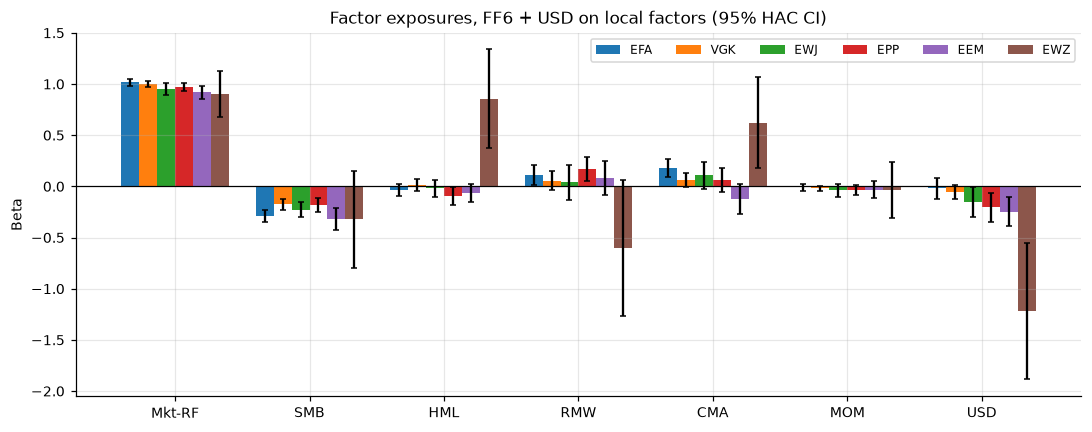

In [6]:
coefs = {t: models.coef_table(r["FF6+USD"]) for t, r in fits.items()}
display(pd.DataFrame({t: c["coef"] for t, c in coefs.items()}).T)
fig = plots.exposure_bars(coefs, "Factor exposures, FF6 + USD on local factors (95% HAC CI)")
save(fig, "02_exposures")

## 6. Global vs local factors (integration vs segmentation)
Same FF6 specification and months; only the factor region changes. If local factors explain
returns much better, the market behaves as if partly **segmented** from global risk pricing.

alpha_ann  alpha_t  beta_mkt  adj_r2  n_months
ETF factors                                                
EFA global      -0.035   -3.361     1.050   0.914   260.000
    local       -0.012   -2.874     1.023   0.980   260.000
VGK global      -0.040   -2.916     1.150   0.896   258.000
    local       -0.004   -1.050     1.017   0.986   258.000
EWJ global      -0.011   -0.694     0.777   0.634   260.000
    local       -0.006   -0.906     0.989   0.895   260.000
EPP global      -0.027   -1.356     1.126   0.772   260.000
    local       -0.007   -1.036     1.024   0.952   260.000
EEM global      -0.009   -0.380     1.063   0.697   260.000
    local       -0.006   -0.673     0.987   0.949   260.000
EWZ global      -0.019   -0.335     1.224   0.439   260.000
    local       -0.038   -0.944     1.173   0.655   260.000

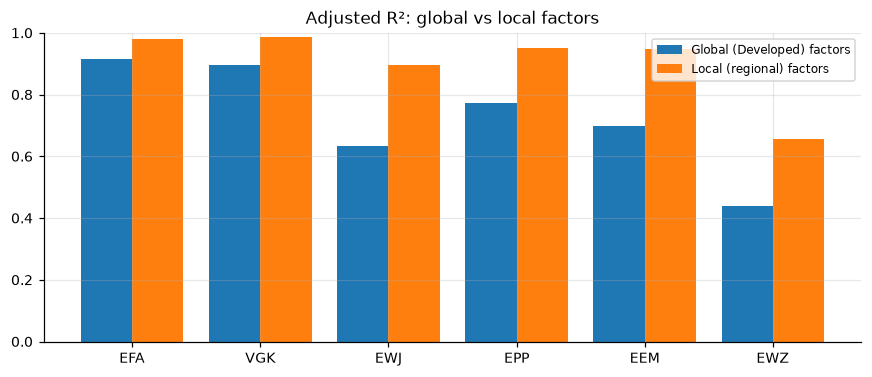

In [7]:
gvl = pd.concat({t: models.global_vs_local(rets[t], factors[region], factors[GLOBAL_REGION])
                 for t, (_, region) in ETFS.items()}, names=["ETF", "factors"])
display(gvl)
fig = plots.global_vs_local_bars(gvl["adj_r2"].unstack())
save(fig, "03_global_vs_local")

## 7. Rolling 36-month exposures
Each point uses only the trailing 36 months, i.e. what an analyst could have measured at that date.

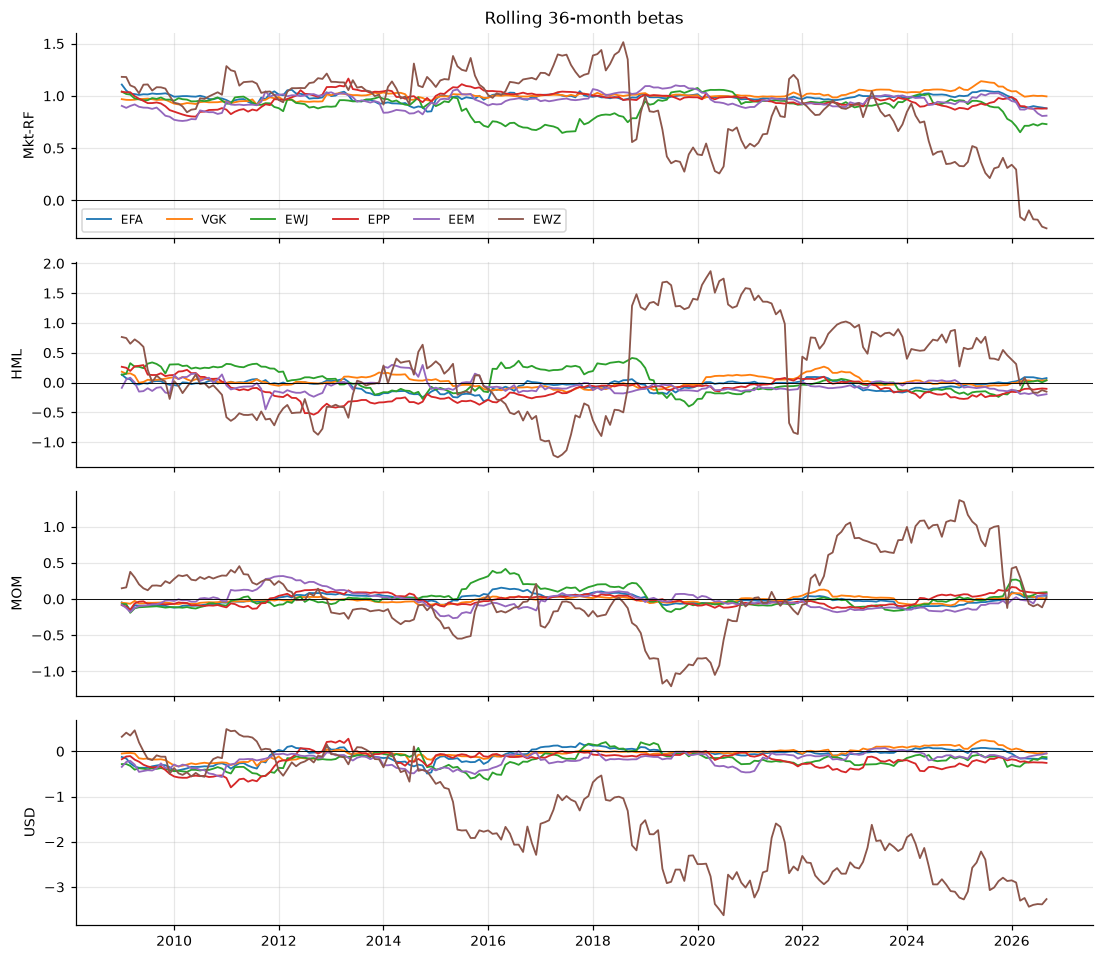

In [8]:
rolling = {t: models.rolling_betas(aligned[t], models.FF6 + ["USD"], WINDOW).dropna() for t in ETFS}
fig = plots.rolling_beta_grid(rolling, ["Mkt-RF", "HML", "MOM", "USD"], WINDOW)
save(fig, "04_rolling_betas")

## 8. Return attribution
Average annualized excess return split into alpha + Σ beta × factor premium. Components sum to the
ETF's annualized mean excess return (arithmetic, ×12); the in-sample residual averages to zero.

,Mkt-RF,SMB,HML,RMW,CMA,MOM,USD,alpha
EFA,0.058,0.001,-0.001,0.002,0.003,-0.001,-0.000,-0.011
VGK,0.062,-0.001,0.000,0.002,0.000,-0.002,-0.001,-0.002
EWJ,0.042,-0.000,-0.001,-0.000,0.003,-0.000,-0.002,-0.004
EPP,0.067,0.003,-0.005,0.007,0.001,-0.003,-0.002,-0.002
EEM,0.067,0.002,-0.004,0.003,-0.003,-0.003,-0.003,-0.001
EWZ,0.066,0.002,0.049,-0.019,0.015,-0.004,-0.014,-0.023


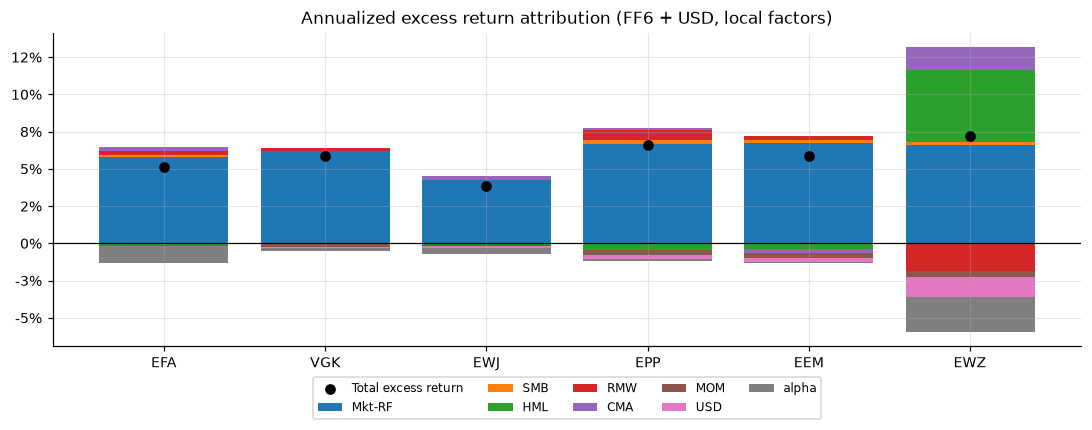

In [9]:
attr = pd.DataFrame({t: models.attribution(fits[t]["FF6+USD"], aligned[t]) for t in ETFS}).T
attr = attr.drop(columns="residual")
assert np.allclose(attr.sum(axis=1), pd.Series({t: aligned[t]["y"].mean() * 12 for t in ETFS}))
display(attr)
fig = plots.attribution_bars(attr, "Annualized excess return attribution (FF6 + USD, local factors)")
save(fig, "05_attribution")

## 9. Residual diagnostics
- **Fitted vs realized**: how close points lie to the 45° line.
- **Cumulative alpha + residual**: a steady downward drift is a cost the factors do not capture
  (expense ratio, dividend withholding tax, index differences).
- **Residual autocorrelation**: negative lag-1 autocorrelation means a one-day timing mismatch (ETFs
  are priced at the New York close; local factors at local market closes) that reverses next month.
  A lagged market term tests the alternative explanation of slow price adjustment.

,resid_ac1,resid_ac2,lagged_mkt_beta,lagged_mkt_t
EFA,-0.358,-0.026,0.015,1.106
VGK,-0.356,0.012,-0.002,-0.272
EWJ,-0.410,-0.061,0.003,0.077
EPP,-0.274,-0.074,-0.007,-0.275
EEM,-0.322,-0.137,-0.013,-0.630
EWZ,-0.107,-0.075,0.024,0.371


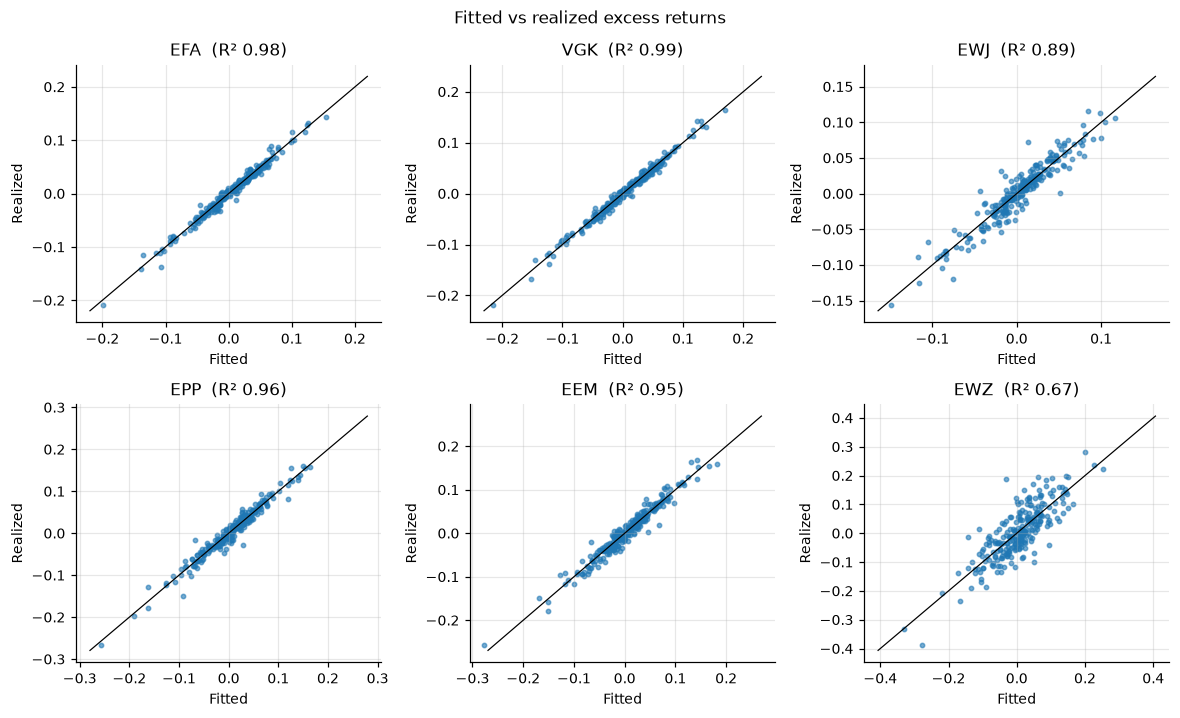

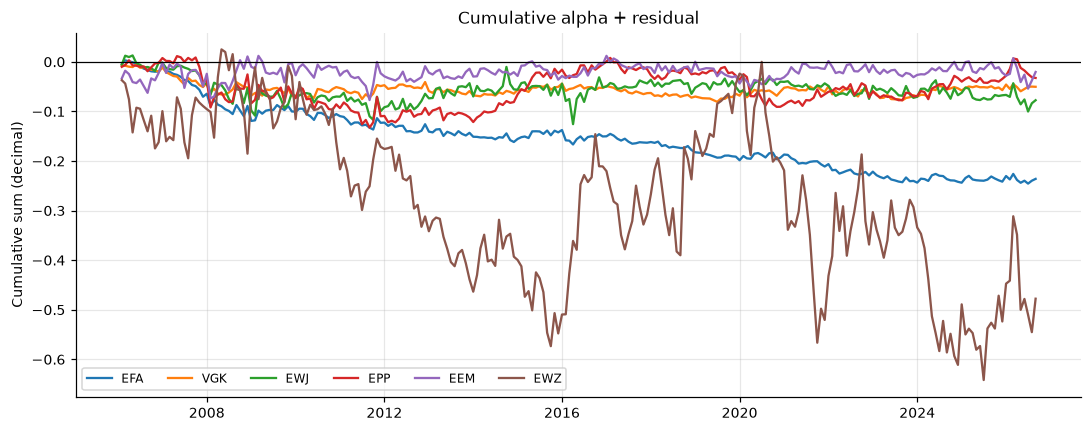

In [10]:
best = {t: (fits[t]["FF6+USD"], aligned[t]) for t in ETFS}
save(plots.fitted_vs_realized(best), "06_fitted_vs_realized")
save(plots.cumulative_residuals(best), "07_cumulative_residuals")

rows = {}
for t in ETFS:
    res, d = best[t]
    lagged = d.assign(Mkt_lag=d["Mkt-RF"].shift(1)).dropna()
    r_lag = models.fit(lagged, models.FF6 + ["USD", "Mkt_lag"])
    rows[t] = {"resid_ac1": res.resid.autocorr(1), "resid_ac2": res.resid.autocorr(2),
               "lagged_mkt_beta": r_lag.params["Mkt_lag"], "lagged_mkt_t": r_lag.tvalues["Mkt_lag"]}
diag = pd.DataFrame(rows).T
display(diag)

## 10. Stability: did exposures change?
HAC Wald test that alpha and all betas are equal before and after the split month (Chow-type test).

In [11]:
stab_rows, stab_tables = {}, {}
for t in ETFS:
    table, stat, p = models.stability_test(aligned[t], models.FF6 + ["USD"], SPLIT)
    stab_tables[t] = table
    stab_rows[t] = {"wald_chi2": stat, "p_value": p,
                    "mkt_beta_pre": table.loc["Mkt-RF", "pre"], "mkt_beta_post": table.loc["Mkt-RF", "post"],
                    "usd_beta_pre": table.loc["USD", "pre"], "usd_beta_post": table.loc["USD", "post"]}
stability = pd.DataFrame(stab_rows).T
display(stability)

,wald_chi2,p_value,mkt_beta_pre,mkt_beta_post,usd_beta_pre,usd_beta_post
EFA,10.480,0.233,1.039,0.992,-0.050,0.006
VGK,18.514,0.018,0.991,1.018,-0.082,-0.005
EWJ,13.566,0.094,0.984,0.928,-0.244,-0.001
EPP,17.416,0.026,0.994,0.948,-0.236,-0.176
EEM,19.679,0.012,0.882,0.953,-0.337,-0.125
EWZ,33.810,0.000,0.985,0.669,-0.463,-2.174


## 11. Export tables

In [12]:
summary.to_csv(TAB_DIR / "model_summary.csv")
pd.concat(coefs, names=["ETF", "term"]).to_csv(TAB_DIR / "coefficients_ff6_usd.csv")
gvl.to_csv(TAB_DIR / "global_vs_local.csv")
attr.to_csv(TAB_DIR / "attribution.csv")
diag.to_csv(TAB_DIR / "residual_diagnostics.csv")
stability.to_csv(TAB_DIR / "stability.csv")
print("Saved tables to", TAB_DIR, "and figures to", FIG_DIR)

Saved tables to /Users/a3357/Desktop/prjject/reports/tables and figures to /Users/a3357/Desktop/prjject/reports/figures


## 12. Limitations
- French factors are built from Bloomberg stock data and are not the MSCI indices the ETFs track
  (e.g. `Developed_ex_US` includes Canada, MSCI EAFE does not). Part of each alpha is index mismatch.
- ETF returns are net of fees and foreign dividend withholding taxes; factor returns are not.
- The USD factor is a non-traded index change, so its coefficient is a sensitivity, not a priced premium.
- Survivorship is not an issue for the fixed ETF list, but the list itself was chosen today.
- Alphas and betas are conditional on the model and the 2006–2026 sample.